In [1]:
import PIL
from PIL import Image
import os
import numpy as np
from tensorflow import keras
import tensorflow as tf
from keras import models,layers
from keras.models import Sequential
import matplotlib.pyplot as plt

In [2]:
import pathlib
data_dir=pathlib.Path("/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages")
data_dir

PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages')

# Check images

In [3]:
list(data_dir.glob('*/*.jpg'))[:5]

[PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/9733.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/63.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/6400.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/823.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/4217.jpg')]

In [4]:
image_count=len(list(data_dir.glob('*/*.jpg')))
print(image_count)

25000


# Create cat and dog image lists

In [5]:
cats=list(data_dir.glob('Cat/*'))
dogs=list(data_dir.glob('Dog/*'))

In [6]:
cats[:5]

[PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/9733.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/63.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/6400.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/823.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Cat/4217.jpg')]

In [7]:
dogs[:5]

[PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Dog/9733.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Dog/63.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Dog/6400.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Dog/823.jpg'),
 PosixPath('/Users/harshraj/Desktop/Cat-dog_AI_Classifier/cat_and_dog/PetImages/Dog/4217.jpg')]

# show image

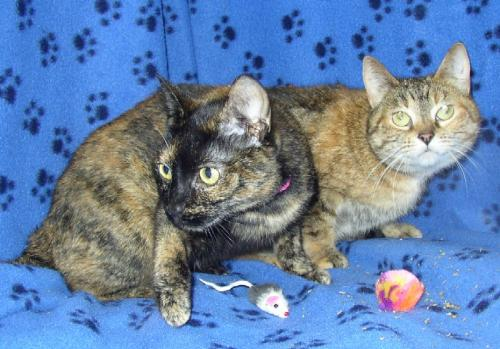

In [8]:
PIL.Image.open(str(cats[150]))

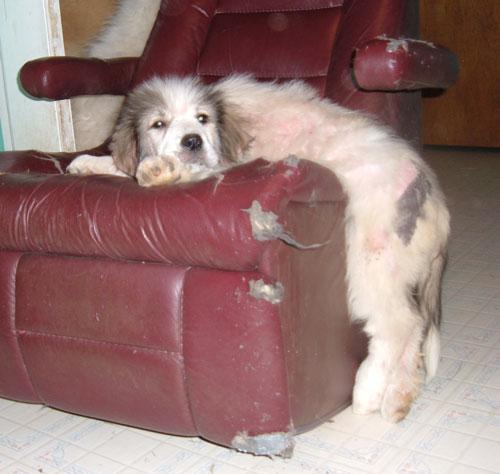

In [9]:
PIL.Image.open(str(dogs[150]))

In [10]:
# Create image dictionary
animal_image_dict={
    'Cat':list(data_dir.glob('Cat/*')),
    'Dog':list(data_dir.glob('Dog/*'))
}

In [11]:
# Create label dictionary
animal_label_dict={
    'Cat': 0,
    'Dog': 1
}

# Check image path

In [12]:
animal_image_dict['Cat'][:5]

[PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Cat/9733.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Cat/63.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Cat/6400.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Cat/823.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Cat/4217.jpg')]

In [13]:
animal_image_dict['Dog'][:5]

[PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Dog/9733.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Dog/63.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Dog/6400.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Dog/823.jpg'),
 PosixPath('/Users/harshraj/Desktop/Deep Learning/CNN/cat_and_dog/PetImages/Dog/4217.jpg')]

In [14]:
import cv2

In [15]:
img=cv2.imread(str(animal_image_dict['Cat'][0]))
img.shape

(500, 365, 3)

In [16]:
# resize the img
resized_img=cv2.resize(img,(180,180))

In [17]:
resized_img.shape

(180, 180, 3)

In [18]:
X,y=[],[]
for animal_name, images in animal_image_dict.items():
    for image in images:
        img=cv2.imread(str(image))
        # Skip images that OpenCV cannot read
        if img is None:
            continue
        # Resize EACH image
        resized_img=cv2.resize(img, (180, 180))
        X.append(resized_img)
        y.append(animal_label_dict[animal_name])

Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9


In [19]:
# X,y=[],[]
# for animal_name, images in animal_image_dict.items():
#     for image in images:
#         img=cv2.imread(str(image))
#         resized_img=cv2.resize(img,(180, 180))
#         X.append(resized_img)
#         y.append(animal_label_dict[animal_name])

In [20]:
X=np.array(X)
y=np.array(y)

In [21]:
X.shape

(24997, 180, 180, 3)

In [22]:
y.shape

(24997,)

In [23]:
# Train Test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=0)

In [24]:
# Preprocessing:Scale images
X_train=X_train/255.0
X_test=X_test/255.0

In [25]:
# Build CNN

model=Sequential([
    layers.Input(shape=(180, 180, 3)),
    layers.Conv2D(16,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(1,activation='sigmoid')
])

model.compile(
    optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

model.fit(X_train,y_train,epochs=10)

Epoch 1/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 93s 156ms/step - accuracy: 0.6639 - loss: 0.6058
Epoch 2/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 107s 182ms/step - accuracy: 0.7627 - loss: 0.4898
Epoch 3/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 100s 170ms/step - accuracy: 0.8105 - loss: 0.4161
Epoch 4/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 105s 180ms/step - accuracy: 0.8483 - loss: 0.3432
Epoch 5/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 120s 204ms/step - accuracy: 0.8955 - loss: 0.2488
Epoch 6/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 124s 211ms/step - accuracy: 0.9468 - loss: 0.1422
Epoch 7/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 130s 222ms/step - accuracy: 0.9722 - loss: 0.0786
Epoch 8/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 123s 210ms/step - accuracy: 0.9851 - loss: 0.0453
Epoch 9/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 127s 216ms/step - accuracy: 0.9910 - loss: 0.0284
Epoch 10/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 144s 245ms/step - accuracy: 0.9935 - loss: 0.0222


In [26]:
model.evaluate(X_test,y_test)

196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - accuracy: 0.7862 - loss: 1.0760


[1.0759930610656738, 0.7862399816513062]

# Data Augmentation

In [27]:
img_height=180
img_width=180
data_augmentation=keras.Sequential([
    layers.RandomFlip("horizontal",input_shape=(img_height,img_width,3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [28]:
print(X.shape)

(24997, 180, 180, 3)


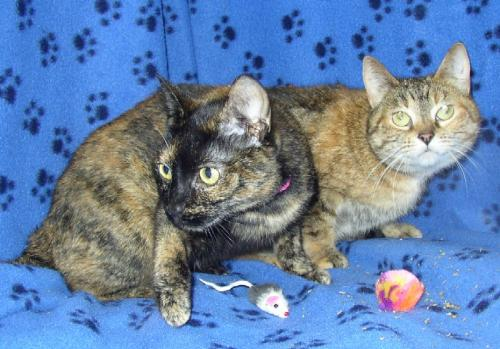

In [29]:
PIL.Image.open(str(cats[150]))

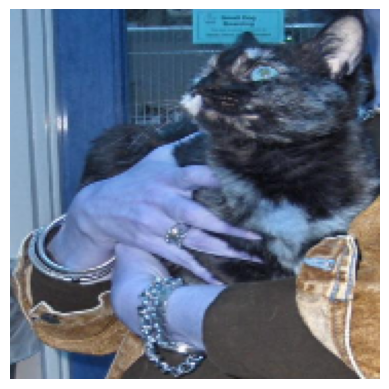

In [30]:
plt.axis('off')
plt.imshow(X[0])

In [31]:
model=Sequential([
    data_augmentation,
    layers.Conv2D(16,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(1,activation='sigmoid')
])

model.compile(
    optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

model.fit(X_train,y_train,epochs=10)

Epoch 1/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 131s 222ms/step - accuracy: 0.6416 - loss: 0.6289
Epoch 2/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 177s 302ms/step - accuracy: 0.7249 - loss: 0.5404
Epoch 3/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 156s 266ms/step - accuracy: 0.7551 - loss: 0.5055
Epoch 4/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 161s 275ms/step - accuracy: 0.7748 - loss: 0.4709
Epoch 5/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 196s 334ms/step - accuracy: 0.7927 - loss: 0.4438
Epoch 6/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 247s 420ms/step - accuracy: 0.8009 - loss: 0.4283
Epoch 7/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 161s 274ms/step - accuracy: 0.8145 - loss: 0.4058
Epoch 8/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 162s 276ms/step - accuracy: 0.8219 - loss: 0.3923
Epoch 9/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 188s 320ms/step - accuracy: 0.8296 - loss: 0.3787
Epoch 10/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 226s 386ms/step - accuracy: 0.8351 - loss: 0.3686


In [32]:
model.evaluate(X_test,y_test)

196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.8506 - loss: 0.3379


[0.3378761410713196, 0.8505600094795227]

In [ ]:
import os
os.makedirs("model",exist_ok=True)
model.save("model/cat_dog_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


In [36]:
model.save("model/cat_dog_cnn.keras")